# 05 — Split sensitivity and error-driver analysis (for the MIDI 2026 paper)

Run order: **cells 1–4 first** (seconds, no GPU). They show how much same-sequence overlap remains in your current split.
Cells 5–7 train two extra YOLO11n models (~4 h each on a T4; run each in its own session). Cell 8 is a cheap box-size analysis.

In [1]:
# 1. Setup
from pathlib import Path
import re, json, shutil, time
import numpy as np, pandas as pd
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = Path('/content/drive/MyDrive/dissertation_weed_detection')
SPLIT_MANIFEST = PROJECT_ROOT/'01_data'/'splits'/'split_manifest.csv'
OUT_DIR = PROJECT_ROOT/'results'/'05_split_sensitivity'
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42

df = pd.read_csv(SPLIT_MANIFEST)
need = {'image_id','image_path','annotation_path','image_filename','near_duplicate_group','split'}
assert need <= set(df.columns), f'missing columns: {need - set(df.columns)}'
print(len(df), df['split'].value_counts().to_dict())

Mounted at /content/drive
6656 {'train': 5326, 'val': 668, 'test': 662}


In [2]:
# 2. Sequence identifier from the filename (6 digits before the first underscore)
def sequence_id(fname):
    m = re.match(r'^.{12}(\d{6})_', fname) or re.search(r'(\d{6})_', fname)
    return m.group(1) if m else None

df['sequence_id'] = df['image_filename'].map(sequence_id)
assert df['sequence_id'].notna().all(), df[df['sequence_id'].isna()].head()

sizes = df.groupby('sequence_id').size()
print('distinct sequence ids :', len(sizes))
print('images per sequence   : min', sizes.min(), '| median', int(sizes.median()), '| max', sizes.max())

# Do the pHash groups from notebook 02 stay inside one sequence id?
g_size = df.groupby('near_duplicate_group').size()
g_seq  = df.groupby('near_duplicate_group')['sequence_id'].nunique()
multi = g_size > 1
print('multi-image pHash groups:', int(multi.sum()), '| inside a single sequence id:', int((multi & (g_seq == 1)).sum()))

distinct sequence ids : 236
images per sequence   : min 1 | median 26 | max 98
multi-image pHash groups: 134 | inside a single sequence id: 132


split  images  images_whose_sequence_is_in_train  percent
  val     668                                667     99.9
 test     662                                661     99.8

sequence ids: 236 | spanning more than one split: 201


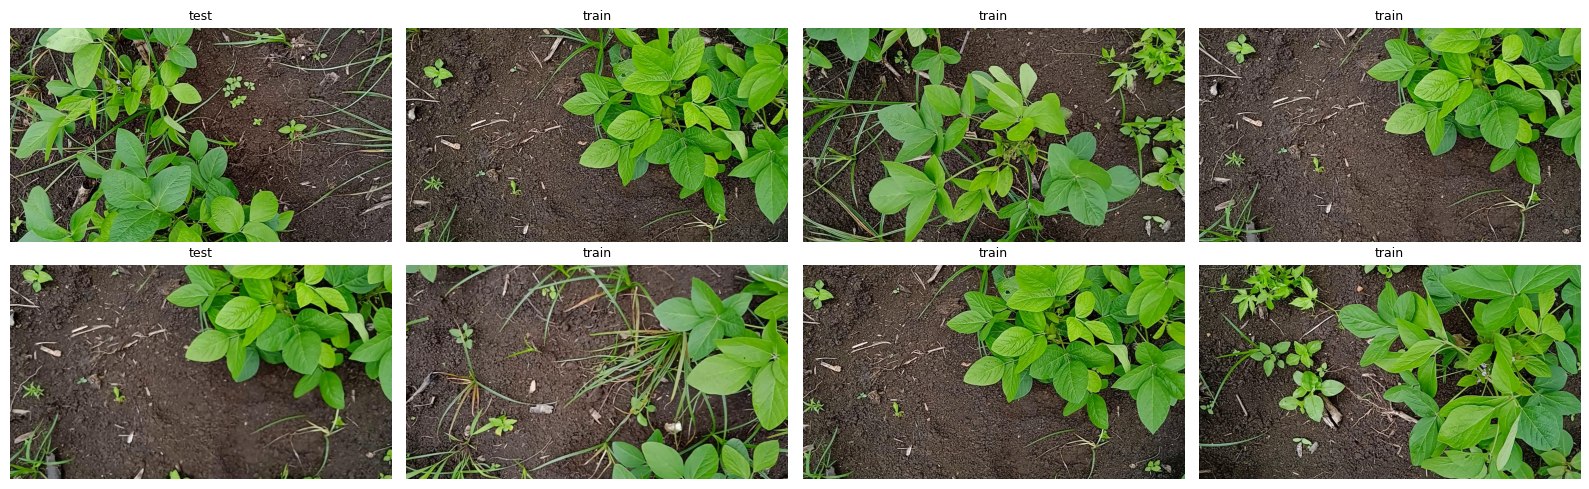

In [3]:
# 3. LEAKAGE AUDIT of the existing pHash-group split w.r.t. sequence ids
tr_seq = set(df.loc[df.split == 'train', 'sequence_id'])
rows = []
for sp in ['val', 'test']:
    sub = df[df.split == sp]
    seen = sub['sequence_id'].isin(tr_seq)
    rows.append((sp, len(sub), int(seen.sum()), round(100*seen.mean(), 1)))
print(pd.DataFrame(rows, columns=['split','images','images_whose_sequence_is_in_train','percent']).to_string(index=False))

span = df.groupby('sequence_id')['split'].nunique()
print('\nsequence ids:', len(span), '| spanning more than one split:', int((span > 1).sum()))

# Visual check that one sequence id really is one scene: 8 images from the largest sequence
import matplotlib.pyplot as plt
from PIL import Image
big = sizes.idxmax()
sample = df[df.sequence_id == big].sample(8, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(16, 5))
for ax, r in zip(axes.ravel(), sample.itertuples()):
    ax.imshow(Image.open(r.image_path).convert('RGB')); ax.axis('off'); ax.set_title(f'{r.split}', fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR/'largest_sequence_contact_sheet.png', dpi=120); plt.show()

In [4]:
# 4. Load annotations (valid boxes only) and per-image class sets
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
CACHE = OUT_DIR/'ann_cache.json'

def load_one(args):
    image_id, path = args
    boxes, bad = [], 0
    for o in json.load(open(path)):
        c, xc, yc, w, h = int(o['class_id']), o['x_center'], o['y_center'], o['width'], o['height']
        if 0 <= c <= 14 and 0 <= xc <= 1 and 0 <= yc <= 1 and 0 < w <= 1 and 0 < h <= 1:
            boxes.append((c, xc, yc, w, h))
        else:
            bad += 1
    return image_id, boxes, bad

if CACHE.exists():
    cached = json.load(open(CACHE))
    ANN = {k: [tuple(b) for b in v] for k, v in cached['ann']}
    invalid = cached['invalid']
    print('loaded annotations from cache')
else:
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=32) as ex:
        results = list(tqdm(ex.map(load_one, zip(df['image_id'], df['annotation_path'])), total=len(df)))
    ANN = {i: b for i, b, _ in results}
    invalid = sum(bad for _, _, bad in results)
    json.dump({'ann': [[i, b] for i, b in ANN.items()], 'invalid': invalid}, open(CACHE, 'w'))
    print(f'loaded in {time.time()-t0:.0f}s, cached to {CACHE.name}')

print('valid boxes:', sum(len(v) for v in ANN.values()), '| invalid:', invalid, '(notebook 04 reported 62,040 valid / 12 invalid)')
df['classes'] = df['image_id'].map(lambda i: sorted({b[0] for b in ANN[i]}))

  0%|          | 0/6656 [00:00<?, ?it/s]

loaded in 97s, cached to ann_cache.json
valid boxes: 62040 | invalid: 12 (notebook 04 reported 62,040 valid / 12 invalid)


In [5]:
# 5. Build the two comparison splits (same 5326/668/662 sizes as the baseline)
from sklearn.model_selection import StratifiedGroupKFold

def random_image_split(n, n_train=5326, n_val=668, seed=SEED):
    idx = np.random.RandomState(seed).permutation(n)
    s = np.empty(n, dtype=object)
    s[idx[:n_train]] = 'train'; s[idx[n_train:n_train+n_val]] = 'val'; s[idx[n_train+n_val:]] = 'test'
    return s

def sequence_group_split(frame, min_per_class=3, seed0=SEED, tries=200):
    img_per_class = pd.Series([c for cl in frame['classes'] for c in cl]).value_counts()
    y = frame['classes'].map(lambda cl: min(cl, key=lambda c: img_per_class[c]) if cl else -1).values
    groups = frame['sequence_id'].values
    for seed in range(seed0, seed0 + tries):
        folds = [te for _, te in StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed).split(frame, y, groups)]
        s = np.full(len(frame), 'train', dtype=object)
        s[folds[0]] = 'test'; s[folds[1]] = 'val'
        ok = True
        for sp in ['val', 'test']:
            cnt = pd.Series([c for cl in frame.loc[s == sp, 'classes'] for c in cl]).value_counts()
            ok &= all(cnt.get(c, 0) >= min_per_class for c in range(15))
        if ok:
            return s, seed
    raise RuntimeError('no seed gave full class coverage; lower min_per_class')

df['split_random']   = random_image_split(len(df))
df['split_sequence'], used_seed = sequence_group_split(df)
print('sequence-group split seed:', used_seed)

for col in ['split_random', 'split_sequence']:
    print('\n', col, df[col].value_counts().to_dict())
tr = set(df.loc[df.split_sequence == 'train', 'sequence_id'])
assert not (set(df.loc[df.split_sequence != 'train', 'sequence_id']) & tr), 'sequence leakage!'
print('\nsequence-group split: zero sequence ids shared with train  OK')
print('\nimages per class (train/val/test), sequence split:')
print(pd.DataFrame({sp: pd.Series([c for cl in df.loc[df.split_sequence == sp, 'classes'] for c in cl]).value_counts().sort_index()
                    for sp in ['train','val','test']}).to_string())
df.to_csv(OUT_DIR/'split_manifest_with_alt_splits.csv', index=False)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=10.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=10.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=10.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=10.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:1023: UserWarning: The least populated class in y has only 8 members, which is less than n_splits=10.
  warnings.warn(
/usr/local/lib/python3.13/dist-pack

sequence-group split seed: 54

 split_random {'train': 5326, 'val': 668, 'test': 662}

 split_sequence {'train': 5152, 'val': 760, 'test': 744}

sequence-group split: zero sequence ids shared with train  OK

images per class (train/val/test), sequence split:
    train  val  test
0    2631  371   375
1    3904  574   580
2    4325  608   613
3    1041  161   154
4     863  101    57
5     797  157   137
6     142   14    17
7     151   25    10
8     498   49    68
9     596   55    70
10    250   34    59
11     67   14     7
12    271   31    31
13     28    7    20
14    184   27    17


In [6]:
# 6. YOLO dataset builder + RESUMABLE train/test runner (config identical to notebook 04, plus RAM image cache)
def build_yolo_dataset(split_col, root):
    root = Path(root)
    if root.exists(): shutil.rmtree(root)
    for sp in ['train', 'val', 'test']:
        (root/'images'/sp).mkdir(parents=True); (root/'labels'/sp).mkdir(parents=True)
    for r, sp in zip(df.itertuples(), df[split_col]):
        img = Path(r.image_path)
        shutil.copy2(img, root/'images'/sp/img.name)
        lines = [f'{c} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}' for c, xc, yc, w, h in ANN[r.image_id]]
        (root/'labels'/sp/(img.stem + '.txt')).write_text('\n'.join(lines))
    (root/'data.yaml').write_text(
        f'path: {root}\ntrain: images/train\nval: images/val\ntest: images/test\nnc: 15\nnames: ' +
        json.dumps({i: str(i) for i in range(15)}))
    return root/'data.yaml'

def train_and_test(name, split_col, epochs=100):
    from ultralytics import YOLO
    done = OUT_DIR/f'{name}_results.json'
    if done.exists():
        print('already done:', done); return json.load(open(done))

    run_dir = OUT_DIR/f'{name}_train'
    last, best = run_dir/'weights'/'last.pt', run_dir/'weights'/'best.pt'
    root = Path(f'/content/yolo_{name}')
    yaml_path = root/'data.yaml' if (root/'data.yaml').exists() else build_yolo_dataset(split_col, root)

    if last.exists():                      # continue an interrupted run from its last saved epoch
        print('Resuming from', last)
        try:
            YOLO(str(last)).train(resume=True)
        except Exception as e:
            if 'finished' in str(e) or 'nothing to resume' in str(e):
                print('Training had already finished; going straight to test evaluation.')
            else:
                raise
    else:                                  # fresh run
        YOLO('yolo11n.pt').train(data=str(yaml_path), epochs=epochs, imgsz=640, batch=16, device=0,
            workers=2, seed=SEED, deterministic=True, patience=20, plots=True, cache='ram',
            project=str(OUT_DIR), name=f'{name}_train', exist_ok=True)

    m = YOLO(str(best)).val(data=str(yaml_path), split='test', imgsz=640, batch=16, device=0, workers=2,
                            seed=SEED, project=str(OUT_DIR), name=f'{name}_test', exist_ok=True)
    res = {'split': name, 'precision': float(m.box.mp), 'recall': float(m.box.mr),
           'mAP50': float(m.box.map50), 'mAP50_95': float(m.box.map),
           'per_class_mAP50_95': [float(v) for v in m.box.maps]}
    json.dump(res, open(done, 'w'), indent=2)
    return res

In [7]:
# 7a. Progress check: how far did an interrupted run get? (no training; safe to run any time)
for name in ['sequence_group', 'random_image']:
    d = OUT_DIR/f'{name}_train'
    if (d/'results.csv').exists():
        r = pd.read_csv(d/'results.csv'); r.columns = [c.strip() for c in r.columns]
        print(f"{name}: {len(r)} epochs finished | last.pt saved: {(d/'weights'/'last.pt').exists()} | best val mAP50-95 so far: {r['metrics/mAP50-95(B)'].max():.3f}")
    else:
        print(f'{name}: no saved run yet')

sequence_group: 33 epochs finished | last.pt saved: True | best val mAP50-95 so far: 0.122
random_image: 100 epochs finished | last.pt saved: True | best val mAP50-95 so far: 0.328


In [8]:
# Install ultralytics dependency
!pip install -q ultralytics

# 7b. THE RUN THAT MATTERS: sequence-group split. Re-running this cell resumes from the last saved epoch.
# The random-image run is skipped on purpose: the pHash baseline is already a near-random split
# (only 5.3% of images are linked into groups). Add train_and_test('random_image','split_random') only if wanted.
res_sequence = train_and_test('sequence_group', 'split_sequence')
print(res_sequence['mAP50'], res_sequence['mAP50_95'])

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Resuming from /content/drive/MyDrive/dissertation_weed_detection/results/05_split_sensitivity/sequence_group_train/weights/last.pt
Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/yolo_sequence_group/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False

In [9]:
# 7c. Summary table for the paper
base = json.load(open(next((PROJECT_ROOT/'results').glob('baseline_yolo_*/test_evaluation/official_baseline_test_metrics.json'))))['metrics']
rows = [('pHash-group (baseline, nb 03/04)', base['precision'], base['recall'], base['mAP50'], base['mAP50_95'])]
for name, label in [('random_image', 'Random image-level'), ('sequence_group', 'Sequence-group')]:
    p = OUT_DIR/f'{name}_results.json'
    if p.exists():
        r = json.load(open(p)); rows.append((label, r['precision'], r['recall'], r['mAP50'], r['mAP50_95']))
print(pd.DataFrame(rows, columns=['protocol','P','R','mAP50','mAP50-95']).round(3).to_string(index=False))

                        protocol     P     R  mAP50  mAP50-95
pHash-group (baseline, nb 03/04) 0.671 0.611  0.639     0.316
              Random image-level 0.692 0.611  0.651     0.309
                  Sequence-group 0.370 0.360  0.326     0.156


In [ ]:
# 7d. NO GPU NEEDED: evaluate a checkpoint on a split's TEST set (CPU, a few minutes).
def evaluate_checkpoint(name, split_col, ckpt='best.pt', final=False):
    from ultralytics import YOLO
    run_dir = OUT_DIR/f'{name}_train'
    weights = run_dir/'weights'/ckpt
    assert weights.exists(), f'{weights} not found'
    epochs_done = len(pd.read_csv(run_dir/'results.csv'))
    root = Path(f'/content/yolo_{name}_testonly')
    if root.exists(): shutil.rmtree(root)
    (root/'images'/'test').mkdir(parents=True); (root/'labels'/'test').mkdir(parents=True)
    for r, sp in zip(df.itertuples(), df[split_col]):
        if sp != 'test': continue
        img = Path(r.image_path)
        shutil.copy2(img, root/'images'/'test'/img.name)
        lines = [f'{c} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}' for c, xc, yc, w, h in ANN[r.image_id]]
        (root/'labels'/'test'/(img.stem + '.txt')).write_text('\n'.join(lines))
    (root/'data.yaml').write_text(f'path: {root}\ntrain: images/test\nval: images/test\ntest: images/test\nnc: 15\nnames: ' +
                                  json.dumps({i: str(i) for i in range(15)}))
    m = YOLO(str(weights)).val(data=str(root/'data.yaml'), split='test', imgsz=640, batch=8, device='cpu', workers=2,
                               project=str(OUT_DIR), name=f'{name}_partial_test', exist_ok=True)
    res = {'split': name, 'checkpoint': ckpt, 'epochs_trained': epochs_done, 'partial': not final,
           'precision': float(m.box.mp), 'recall': float(m.box.mr), 'mAP50': float(m.box.map50), 'mAP50_95': float(m.box.map),
           'per_class_mAP50_95': [float(v) for v in m.box.maps]}
    json.dump(res, open(OUT_DIR/(f'{name}_results.json' if final else f'{name}_partial_results.json'), 'w'), indent=2)
    print(f"epochs trained: {epochs_done} | mAP50 {res['mAP50']:.3f} | mAP50-95 {res['mAP50_95']:.3f}")
    return res

res_partial = evaluate_checkpoint('sequence_group', 'split_sequence')

Ultralytics 8.4.201 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,600,453 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2619.3±1082.7 MB/s, size: 430.8 KB)
val: Scanning /content/yolo_sequence_group_testonly/labels/test... 744 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 744/744 1.1Kit/s 0.7s
val: New cache created: /content/yolo_sequence_group_testonly/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 19% ━━────────── 18/93 1.2it/s 24.5s<1:05

In [ ]:
# 7e. FREE diagnostic (CPU, seconds): validation mAP per epoch, random split vs sequence-group split.
import matplotlib.pyplot as plt
col = 'metrics/mAP50-95(B)'
def curve(name):
    r = pd.read_csv(OUT_DIR/f'{name}_train'/'results.csv'); r.columns = [c.strip() for c in r.columns]
    return r[col].values
v_rand, v_seq = curve('random_image'), curve('sequence_group')
k = len(v_seq)
cmp = pd.DataFrame({'epoch': np.arange(1, k+1), 'val_mAP50-95_random': v_rand[:k].round(3), 'val_mAP50-95_sequence': v_seq.round(3)})
print(cmp.iloc[list(range(4, k, 5)) + [k-1]].drop_duplicates().to_string(index=False))
print(f'\nrandom run: best val mAP50-95 {v_rand.max():.3f} at epoch {int(v_rand.argmax())+1} of {len(v_rand)}')
plt.figure(figsize=(5.5, 3.4))
plt.plot(np.arange(1, len(v_rand)+1), v_rand, label='random split (100 epochs)')
plt.plot(np.arange(1, k+1), v_seq, label=f'sequence-group split ({k} epochs so far)')
plt.xlabel('epoch'); plt.ylabel('val mAP@0.50:0.95'); plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(OUT_DIR/'val_curves_random_vs_sequence.png', dpi=200); plt.show()

In [ ]:
# 7f. Test result for the FINISHED random-split run (CPU, a few minutes). Saved as random_image_results.json for cell 7c.
res_random = evaluate_checkpoint('random_image', 'split_random', ckpt='best.pt', final=True)

In [ ]:
# 8. Box-size analysis per class (cheap, no GPU) -- tests the 'small objects' explanation
W, H = 1920, 1080
b = pd.DataFrame([(c, w*W, h*H) for v in ANN.values() for (c, _, _, w, h) in v], columns=['cls', 'w_px', 'h_px'])
b['side'] = np.sqrt(b.w_px * b.h_px)
test_map = [0.4061,0.2335,0.2960,0.5995,0.3783,0.2893,0.3535,0.3294,0.2721,0.1971,0.4299,0.1646,0.2594,0.0820,0.4428]  # baseline, notebook 04
t = b.groupby('cls').agg(boxes=('side','size'), median_side_px=('side','median'),
                         pct_small=('side', lambda s: 100*(s < 32).mean())).round(1)
t['test_mAP50_95'] = test_map
print(t.to_string())
from scipy.stats import spearmanr
print('Spearman(median box side, mAP50-95):', spearmanr(t.median_side_px, t.test_mAP50_95))
print('Spearman(box count,       mAP50-95):', spearmanr(t.boxes, t.test_mAP50_95))
t.to_csv(OUT_DIR/'per_class_box_size.csv')